In [41]:
# Week 2 Assessment - Task 1
# Concepts, Splits and Leakage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [42]:
# Load Breast Cancer Dataset

dataset = load_breast_cancer()

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

print("Dataset loaded successfully!")
print("Dataset Shape:", X.shape)
print("\nTarget Distribution:")
print(y.value_counts())
print("\nFeatures:", X.shape[1])

Dataset loaded successfully!
Dataset Shape: (569, 30)

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64

Features: 30


In [43]:
# Split dataset into Train (60%) and Temporary (40%)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Split Temporary data into Validation (20%) and Test (20%)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display dataset sizes

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Test Set:", X_test.shape)

print("\nTotal Samples:", len(X_train) + len(X_val) + len(X_test))

Training Set: (341, 30)
Validation Set: (114, 30)
Test Set: (114, 30)

Total Samples: 569


In [44]:
# Decision Tree - Overfitting Demonstration

depths = [1, 3, 5, 10, None]

train_accuracies = []
val_accuracies = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"Depth {depth}: Train {train_acc:.2f} | Val {val_acc:.2f}")

Depth 1: Train 0.93 | Val 0.94
Depth 3: Train 0.97 | Val 0.96
Depth 5: Train 0.99 | Val 0.96
Depth 10: Train 1.00 | Val 0.96
Depth None: Train 1.00 | Val 0.96


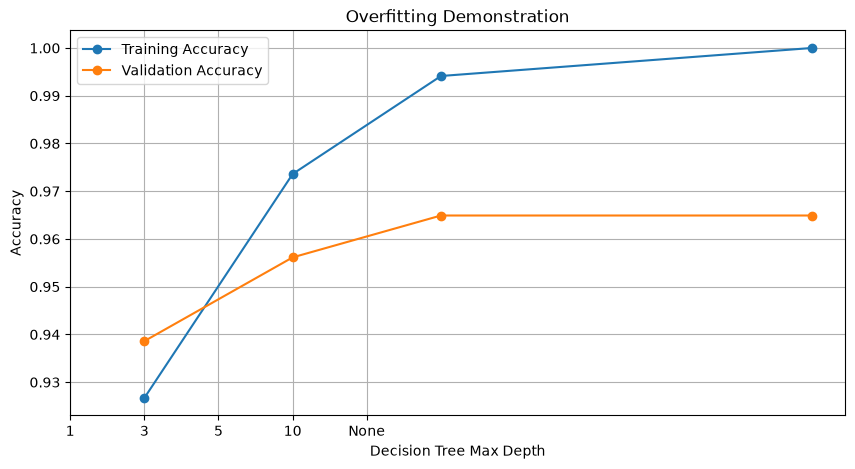

In [45]:
# Plot Train vs Validation Accuracy

plt.figure(figsize=(10, 5))

plt.plot(depths, train_accuracies, marker='o', label='Training Accuracy')
plt.plot(depths, val_accuracies, marker='o', label='Validation Accuracy')

plt.xlabel("Decision Tree Max Depth")
plt.ylabel("Accuracy")
plt.title("Overfitting Demonstration")
plt.xticks(range(len(depths)), ['1', '3', '5', '10', 'None'])
plt.legend()
plt.grid(True)

plt.show()

In [46]:
# 5-Fold Cross Validation - Logistic Regression

from sklearn.pipeline import make_pipeline

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=10000, random_state=42)
)

cv_scores = cross_val_score(
    lr_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Cross Validation Scores:", cv_scores)
print("Mean Accuracy: {:.2f}".format(cv_scores.mean()))
print("Standard Deviation: {:.2f}".format(cv_scores.std()))

Cross Validation Scores: [0.95652174 0.97058824 0.95588235 0.97058824 0.98529412]
Mean Accuracy: 0.97
Standard Deviation: 0.01


In [47]:
# Data Leakage Demonstration

# Incorrect Approach: Scaling before splitting

scaler_wrong = StandardScaler()

X_scaled_wrong = scaler_wrong.fit_transform(X)

X_train_wrong, X_temp_wrong, y_train_wrong, y_temp_wrong = train_test_split(
    X_scaled_wrong, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Correct Approach: Split first, then scale

scaler_correct = StandardScaler()

X_train_scaled = scaler_correct.fit_transform(X_train)

X_val_scaled = scaler_correct.transform(X_val)
X_test_scaled = scaler_correct.transform(X_test)

print("Incorrect Scaling Shape:", X_train_wrong.shape)
print("Correct Training Shape:", X_train_scaled.shape)
print("Correct Validation Shape:", X_val_scaled.shape)
print("Correct Test Shape:", X_test_scaled.shape)

print("\nData leakage demonstration completed!")

Incorrect Scaling Shape: (341, 30)
Correct Training Shape: (341, 30)
Correct Validation Shape: (114, 30)
Correct Test Shape: (114, 30)

Data leakage demonstration completed!


In [48]:
## Machine Learning Workflow - 7 Steps

1. Data Collection: Collect relevant data from different sources.
2. Data Understanding: Explore and understand the dataset.
3. Data Preprocessing: Handle missing values, encoding and scaling.
4. Data Splitting: Split data into training, validation and testing sets.
5. Model Training: Select and train suitable machine learning algorithms.
6. Model Evaluation: Evaluate model performance using appropriate metrics.
7. Model Optimization and Deployment: Tune the model and deploy it for real-world use.

SyntaxError: invalid syntax (470202729.py, line 3)

In [ ]:
## Machine Learning Workflow - 7 Steps

1. Data Collection: Collect relevant data from different sources.
2. Data Understanding: Explore and understand the dataset.
3. Data Preprocessing: Handle missing values, encoding and scaling.
4. Data Splitting: Split data into training, validation and testing sets.
5. Model Training: Select and train suitable machine learning algorithms.
6. Model Evaluation: Evaluate model performance using appropriate metrics.
7. Model Optimization and Deployment: Tune the model and deploy it for real-world use.

In [ ]:
## Machine Learning Workflow - 7 Steps

1.  relevant data from different sources.
2. Data Understanding: Explore and understand the dataset.
3. Data Preprocessing: Handle missing values, encoding and scaling.
4. Data Splitting: Split data into training, validation and testing sets.
5. Model Training: Select and train suitable machine learning algorithms.
6. Model Evaluation: Evaluate model performance using appropriate metrics.
7. Model Optimization and Deployment: Tune the model and deploy it for real-world use.

## Machine Learning Workflow - 7 Steps

1. Data Collection: Collect relevant data from different sources.
2. Data Understanding: Explore and understand the dataset.
3. Data Preprocessing: Handle missing values, encoding and scaling.
4. Data Splitting: Split data into training, validation and testing sets.
5. Model Training: Select and train suitable machine learning algorithms.
6. Model Evaluation: Evaluate model performance using appropriate metrics.
7. Model Optimization and Deployment: Tune the model and deploy it for real-world use.